# Semana 3: Neurona leaky integrate-and-fire (LIF)

**Objetivo:** relacionar los parámetros de membrana con la corriente mínima para disparar
(reobase) y con la frecuencia de disparo.

## Modelo

$$\tau_m \frac{dV}{dt} = -(V - V_\text{rest}) + R\,I$$

Si $V \ge V_\text{th}$, se registra un spike, $V \leftarrow V_\text{reset}$ y la neurona queda
refractaria durante $t_\text{ref}$.

| Parámetro | Valor |
|---|---|
| $\tau_m$ | 20 ms |
| $R$ | 10 MΩ |
| $V_\text{rest} = V_\text{reset}$ | −65 mV |
| $V_\text{th}$ | −50 mV |
| $t_\text{ref}$ | 2 ms |

Con corriente constante, el voltaje tiende a $V_\infty = V_\text{rest} + RI$. La neurona solo
dispara si $V_\infty > V_\text{th}$, es decir, por encima de la **reobase**:

$$I_\text{rh} = \frac{V_\text{th} - V_\text{rest}}{R} = \frac{15\ \text{mV}}{10\ \text{M}\Omega} = 1.5\ \text{nA}$$

Por encima de la reobase, integrar la ecuación entre reset y umbral da la frecuencia teórica:

$$f(I) = \left[t_\text{ref} + \tau_m \ln\frac{RI}{RI - (V_\text{th} - V_\text{rest})}\right]^{-1}$$

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from computational_neuroscience import lif_firing_rate, simulate_lif
from computational_neuroscience.outputs import save_data, save_figure

WEEK = 3
R_MOHM, V_REST, V_TH = 10.0, -65.0, -50.0  # package defaults
RHEOBASE_NA = (V_TH - V_REST) / R_MOHM


def simulated_rate_hz(current_na: float, duration_ms: float = 1000.0) -> float:
    spikes = simulate_lif(current_na, duration_ms=duration_ms).spike_times_ms
    return 1000.0 / np.mean(np.diff(spikes)) if spikes.size > 1 else 0.0


example_currents = (1.0, 2.0, 3.0)
examples = [simulate_lif(current, duration_ms=200.0) for current in example_currents]
sweep = np.round(np.arange(0.0, 4.01, 0.1), 2)
simulated = np.array([simulated_rate_hz(current) for current in sweep])
theory = lif_firing_rate(sweep)

## Figura

Arriba: voltaje para una corriente subumbral (1 nA) y dos supraumbrales (2 y 3 nA). Los
spikes se dibujan como líneas verticales (el modelo LIF no genera la forma del potencial de
acción, solo el instante). Abajo: curva f-I simulada frente a la fórmula teórica.

Saved: weeks/week_03_lif_currents/outputs/lif_current_response.png
Saved: weeks/week_03_lif_currents/outputs/lif_current_response.npz


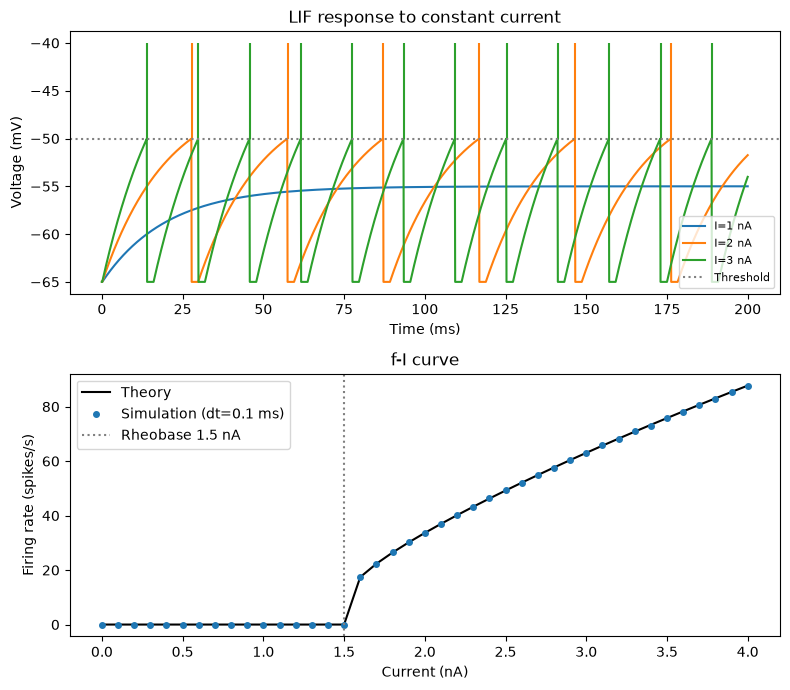

In [2]:
figure, axes = plt.subplots(2, 1, figsize=(8, 7))
for current, result in zip(example_currents, examples):
    line, = axes[0].plot(result.time_ms, result.voltage_mv, label=f"I={current:g} nA")
    axes[0].vlines(result.spike_times_ms, V_TH, V_TH + 10, color=line.get_color())
axes[0].axhline(V_TH, color="grey", linestyle=":", label="Threshold")
axes[0].set(xlabel="Time (ms)", ylabel="Voltage (mV)", title="LIF response to constant current")
axes[0].legend(loc="lower right", fontsize=8)

axes[1].plot(sweep, theory, "k-", label="Theory")
axes[1].plot(sweep, simulated, "o", markersize=4, label="Simulation (dt=0.1 ms)")
axes[1].axvline(RHEOBASE_NA, color="grey", linestyle=":", label=f"Rheobase {RHEOBASE_NA:g} nA")
axes[1].set(xlabel="Current (nA)", ylabel="Firing rate (spikes/s)", title="f-I curve")
axes[1].legend()
save_figure(WEEK, figure, "lif_current_response.png")
save_data(WEEK, "lif_current_response.npz", current_na=sweep, simulated_rate_hz=simulated, theoretical_rate_hz=theory)

## Validación

- Ninguna corriente ≤ reobase produce spikes.
- La frecuencia crece con la corriente.
- La simulación coincide con la fórmula teórica dentro de un 5 % lejos de la reobase
  (cerca de la reobase, el período diverge y el error de discretización pesa más).

In [3]:
assert np.all(simulated[sweep <= RHEOBASE_NA] == 0)
assert np.all(np.diff(simulated[sweep > RHEOBASE_NA]) > 0)
far = sweep >= 1.8
relative_error = np.abs(simulated[far] - theory[far]) / theory[far]
assert relative_error.max() < 0.05, relative_error.max()
for current in example_currents:
    print(f"I={current:g} nA: simulated {simulated_rate_hz(current):.1f} Hz, theory {lif_firing_rate(current):.1f} Hz")
print(f"Max relative error for I >= 1.8 nA: {relative_error.max():.2%}")

I=1 nA: simulated 0.0 Hz, theory 0.0 Hz
I=2 nA: simulated 33.7 Hz, theory 33.6 Hz
I=3 nA: simulated 62.9 Hz, theory 63.0 Hz
Max relative error for I >= 1.8 nA: 0.48%


## Interpretación y límites

- Cerca de la reobase la frecuencia sube muy rápido (el logaritmo diverge); lejos de ella la
  curva se vuelve casi lineal y, a corrientes muy altas, la refractariedad limita la frecuencia a
  $1/t_\text{ref}$ = 500 Hz.
- El LIF no tiene canales iónicos: no explica la forma del spike ni la adaptación.

**Para tu entrega:** predice primero cómo cambia la reobase si duplicas $R$ o $\tau_m$, y
compruébalo con la simulación.